In [23]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100


### You can get helper function to plot decision boundary from given repo:

`https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py`

`import requests`

`request.get(`https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py`)`

In [38]:
#You can get helper function to plot decision boundary from given repo:
#https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py#You can get helper function to plot decision boundary from given repo:
#https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py
from helper_functions import plot_decision_boundary, accuracy_fn

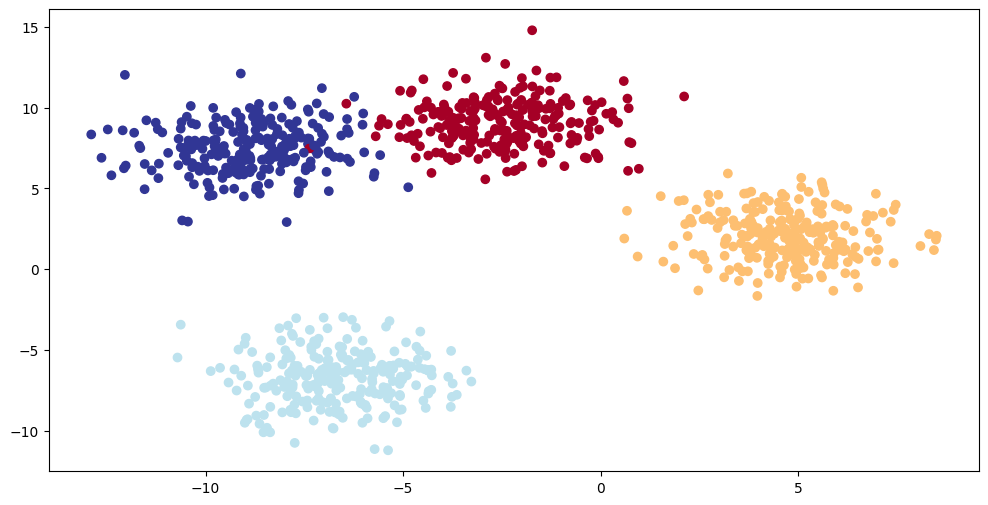

In [39]:
# Import dependencies
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Set the hyperparameterss for data creation
NUM_CLASSES=4
NUM_FEATURES=2
RANDOM_SEED=42    # we generally write hyper parameters that we write at the start at the notebook are written in capital, just a way of saying hey u can change these

#1. Create multi class data
X_blob, y_blob = make_blobs(n_samples=1000,
                            n_features=NUM_FEATURES,
                            centers=NUM_CLASSES,
                            cluster_std=1.5, # give the clusters a little shakeup
                            random_state=RANDOM_SEED)

# 2. Turn dat into tensors
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)

#3. Split into training and test
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob,
                                                                        y_blob,
                                                                        test_size=0.2,
                                                                        random_state=RANDOM_SEED)

#4. Plot data (Visuzlize, visuzlize, visualize)
plt.figure(figsize=(12,6))
plt.scatter(X_blob[:,0], X_blob[:,1], c=y_blob, cmap=plt.cm.RdYlBu)


In [40]:
# Create device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)


# Build a multi class classification model
class BlobModel(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8):
        """Initializes multi-class classification model.

        Args:
            input_features (int): Number of input features to the model
            output_features (int): Number of output features (number of output classes)
            hidden_units (int): Number of hidden units between layers, default 8

        Returns:

        Example:
        """
        super().__init__()
        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features)
        )

    def forward(self, x):
        return self.linear_layer_stack(x)


#Create an instance of BlobModel and send it to the target device
model_4 = BlobModel(input_features=2,
                    output_features=4,
                    hidden_units=8).to(device)
model_4

cuda


BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [41]:
# Create a loss function for multi class classification
loss_fn = nn.CrossEntropyLoss()

#Create an optimizer for multi class classification
optimizer=torch.optim.SGD(params=model_4.parameters(),
                          lr=0.1) #learning rate is a hyperparametere you can change

In [42]:
 #Let's get some raw outputs of our model (logits))
model_4.eval()
with torch.inference_mode():
    y_logits=model_4(X_blob_test.to(device))
y_logits[:10]

tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
        [-0.0973, -0.9431, -0.5963, -0.1371],
        [ 0.2528, -0.2379,  0.1882, -0.0066],
        [-0.4134, -0.5204, -0.9303, -0.6963],
        [-0.3118, -1.3736, -1.1991, -0.3834],
        [-0.1497, -1.0617, -0.7107, -0.1645],
        [ 0.1539, -0.2887,  0.1520, -0.0109],
        [-0.2154, -1.1795, -0.9300, -0.2745],
        [ 0.2443, -0.2472,  0.1649,  0.0061],
        [-0.2329, -1.2120, -0.9849, -0.3004]], device='cuda:0')

In [43]:
print(next(model_4.parameters()).device)
print(X_blob_test.device)

cuda:0
cpu


In [44]:
#Convert our model's logit outputs to prediction probabilites
y_pred_probs=torch.softmax(y_logits,dim=1)

In [45]:
# Convert out model's prediction probabiliteies to predictionlabels
y_preds = torch.argmax(y_pred_probs, dim=1)
y_preds

tensor([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 3, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 1, 0, 1, 0, 0, 0,
        0, 0, 0, 0, 3, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 1, 0, 1], device='cuda:0')

In [46]:
# Fit the multi class model to the data
torch.manual_seed(42)
torch.cuda.manual_seed(42)

#Set number of epochs
epochs=100

#Put data to the target device
X_blob_train, y_blob_train=X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test=X_blob_test.to(device), y_blob_test.to(device)

#Loop through data
for epoch in range(epochs):
    ### Training
    model_4.train()
    y_logits=model_4(X_blob_train)

    y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)

    loss=loss_fn(y_logits, y_blob_train)
    acc=accuracy_fn(y_true=y_blob_train, y_pred=y_pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    ### Testing
    model_4.eval()
    with torch.inference_mode():
        test_logits=model_4(X_blob_test)
        test_preds=torch.softmax(test_logits, dim=1).argmax(dim=1)

        test_loss=loss_fn(test_logits, y_blob_test)
        test_acc=accuracy_fn(y_true=y_blob_test, y_pred=test_preds)
# Print out whats happening
    if epoch %10==0:
        print(f"Epoch: {epoch} | Loss: {loss:.4f} | Acc: {acc:.2f}% | Test loss: {test_loss:.4f} | Test acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 1.1588 | Acc: 40.38% | Test loss: 1.0755 | Test acc: 48.00%
Epoch: 10 | Loss: 0.6448 | Acc: 96.75% | Test loss: 0.6607 | Test acc: 97.50%
Epoch: 20 | Loss: 0.4254 | Acc: 98.50% | Test loss: 0.4307 | Test acc: 100.00%
Epoch: 30 | Loss: 0.2529 | Acc: 99.12% | Test loss: 0.2451 | Test acc: 99.50%
Epoch: 40 | Loss: 0.1123 | Acc: 99.25% | Test loss: 0.1023 | Test acc: 99.50%
Epoch: 50 | Loss: 0.0663 | Acc: 99.25% | Test loss: 0.0585 | Test acc: 99.50%
Epoch: 60 | Loss: 0.0507 | Acc: 99.25% | Test loss: 0.0429 | Test acc: 99.50%
Epoch: 70 | Loss: 0.0430 | Acc: 99.25% | Test loss: 0.0349 | Test acc: 99.50%
Epoch: 80 | Loss: 0.0384 | Acc: 99.25% | Test loss: 0.0299 | Test acc: 99.50%
Epoch: 90 | Loss: 0.0352 | Acc: 99.25% | Test loss: 0.0266 | Test acc: 99.50%


In [47]:
# Make predictions
model_4.eval()
with torch.inference_mode():
    y_logits=model_4(X_blob_train)

#View the first 10 predictions
y_logits[:10]



tensor([[-1.3344,  6.3308, -6.8960, -7.8460],
        [ 3.4175, -4.6882, -7.1541, -3.3469],
        [-4.3207, -4.9367,  3.7790, -3.3399],
        [-2.7649, -3.2697,  2.8040, -2.2441],
        [ 1.7790, -4.4905, -4.9554, -1.3282],
        [ 2.7366,  0.4429, -7.4993, -6.6685],
        [ 2.5785, -6.0076, -7.1173, -1.9804],
        [-0.9690,  4.8266, -5.2035, -6.1433],
        [-2.3246, -5.8080, -2.6661,  2.7026],
        [ 2.1972, -5.1874, -5.9877, -1.6836]], device='cuda:0')

In [48]:
# Go from logits -> Prediction probabilities
y_pred_pros=torch.softmax(y_logits, dim=1)
y_pred_probs[:10]

tensor([[0.3169, 0.3244, 0.1405, 0.2182],
        [0.3336, 0.1432, 0.2026, 0.3206],
        [0.3011, 0.1843, 0.2823, 0.2323],
        [0.3078, 0.2766, 0.1836, 0.2320],
        [0.3719, 0.1286, 0.1532, 0.3463],
        [0.3381, 0.1358, 0.1929, 0.3331],
        [0.2867, 0.1841, 0.2861, 0.2431],
        [0.3554, 0.1355, 0.1740, 0.3351],
        [0.3009, 0.1841, 0.2779, 0.2371],
        [0.3595, 0.1350, 0.1695, 0.3360]], device='cuda:0')

In [49]:
# Go from pred probs to pred labels
y_preds = torch.argmax(y_pred_probs, dim=1)
y_preds[:10]


tensor([1, 0, 0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

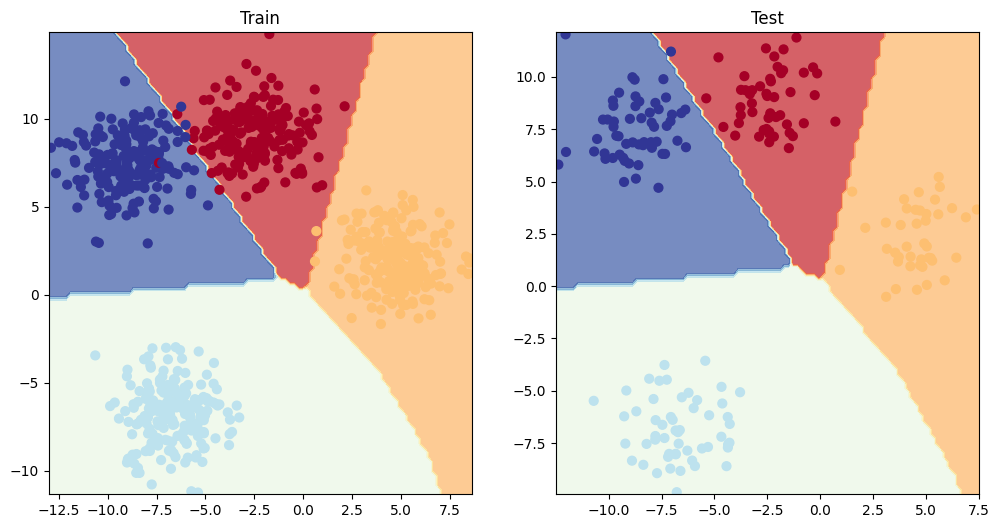

In [50]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test)